# Skip list: analysis of the four methods

Run **Setup** once, then follow the method sections in this order: **Search → Insert → Ordered union → Split**. Each section runs only its own benchmark, saves its raw data, converts its timings, and produces its plot.

The C++ files are already in `google_benchmark/src`. This notebook compiles and runs them; it does not write C++ source. The rebuilding split comparison is included.

The Split section ends with a comparison against `split_rebuild` on the same inputs.

## Setup

### Locate the project

Locally, open this notebook inside the project. On Colab, upload the project ZIP/TAR.GZ when prompted, without build directories or downloaded dependencies. Use a CPU runtime.

Leave `PROJECT_ROOT = None` for automatic discovery, or set it to the extracted project directory. Change `RUN_LABEL` to preserve another run. Set `RERUN_BENCHMARKS = False` to reuse saved JSON and regenerate only statistics and figures; set it to `True` to rebuild and rerun all benchmarks.

In [1]:
from pathlib import Path
import json
import os
import platform
import shutil
import subprocess
import sys
import tempfile

PROJECT_ROOT = None
IN_COLAB = "google.colab" in sys.modules
RUN_LABEL = "colab" if IN_COLAB else "local"
# False reuses saved raw JSON and only recomputes statistics and plots.
# Set True to rebuild and rerun every benchmark.
RERUN_BENCHMARKS = False
MIN_TIME = "0.1s"

if PROJECT_ROOT is not None:
    project_root = Path(PROJECT_ROOT).expanduser().resolve()
else:
    candidates = [Path.cwd(), *Path.cwd().parents]
    project_root = next((p for p in candidates
                         if (p / "google_benchmark/src/search_benchmark.cpp").is_file()
                         and (p / "CMakeLists.txt").is_file()), None)
    if project_root is None and IN_COLAB:
        from google.colab import files
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError("Upload exactly one project ZIP or TAR.GZ archive.")
        archive = next(iter(uploaded))
        extracted = Path(tempfile.mkdtemp(prefix="skip_list_"))
        shutil.unpack_archive(archive, extracted)
        candidates = [p.parents[2] for p in extracted.rglob("search_benchmark.cpp")
                      if p.parent.name == "src" and p.parent.parent.name == "google_benchmark"
                      and (p.parents[2] / "CMakeLists.txt").is_file()]
        if len(candidates) != 1:
            raise ValueError("Cannot identify one project. Set PROJECT_ROOT explicitly.")
        project_root = candidates[0]

if project_root is None or not (project_root / "CMakeLists.txt").is_file():
    raise ValueError("Set PROJECT_ROOT to the directory containing CMakeLists.txt.")
os.chdir(project_root)
print("Project:", project_root)
print("Environment:", RUN_LABEL, platform.platform())
print("Rerun benchmarks:", RERUN_BENCHMARKS)

Saving skip_list.zip to skip_list.zip
Project: /tmp/skip_list_ps9s9sw_/skip_list
Environment: colab Linux-6.6.159+-x86_64-with-glibc2.39
Rerun benchmarks: True


In [2]:
!git clone https://github.com/google/benchmark.git
!git clone https://github.com/google/googletest.git benchmark/googletest

Cloning into 'benchmark'...
remote: Enumerating objects: 11302, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (48/48), done.
remote: Total 11302 (delta 44), reused 19 (delta 18), pack-reused 11235 (from 2)
Receiving objects: 100% (11302/11302), 3.58 MiB | 16.82 MiB/s, done.
Resolving deltas: 100% (7762/7762), done.
Cloning into 'benchmark/googletest'...
remote: Enumerating objects: 29476, done.
remote: Counting objects: 100% (593/593), done.
remote: Compressing objects: 100% (421/421), done.
remote: Total 29476 (delta 427), reused 172 (delta 172), pack-reused 28883 (from 4)
Receiving objects: 100% (29476/29476), 14.29 MiB | 20.72 MiB/s, done.
Resolving deltas: 100% (21845/21845), done.


### Build the benchmark

CMake obtains the pinned Google Benchmark v1.10.0 dependency and builds `skip_list_benchmark` in Release mode. The first build needs internet access. These timing runs use one thread and no sanitizers; correctness and memory checks remain separate.

In [3]:
build_dir = project_root / "build/google_benchmark"
if RERUN_BENCHMARKS:
    missing = [name for name in ("cmake", "git", "c++") if shutil.which(name) is None]
    if missing and IN_COLAB:
        subprocess.run(["apt-get", "update", "-qq"], check=True)
        subprocess.run(["apt-get", "install", "-y", "cmake", "git", "g++"], check=True)
    elif missing:
        raise RuntimeError("Install the missing build tools first: " + ", ".join(missing))
    subprocess.run(["cmake", "-S", str(project_root), "-B", str(build_dir), "-DCMAKE_BUILD_TYPE=Release", "-DBUILD_GOOGLE_BENCHMARK=ON"], check=True)
    subprocess.run(["cmake", "--build", str(build_dir), "--target", "skip_list_benchmark", "skip_list_test", "--parallel", "2"], check=True)
    executable = build_dir / "skip_list_benchmark"
else:
    print("Reusing saved JSON: build and benchmark execution are skipped.")

### Prepare analysis and output directories

All methods use the sizes and height seeds below, with three timing repetitions per seed/size: **54 timing records per method**. Workload settings are defined in `google_benchmark/src/benchmark_support.hpp`.

Search uses `MIN_TIME` for automatic calibration. The other methods use **10 iterations per repetition**, rebuilding inputs while timing is paused. Their untimed setup still takes real time, so allow several minutes for all methods.

In [4]:
try:
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    subprocess.run([sys.executable, "-m", "pip", "install", "pandas", "numpy", "matplotlib"], check=True)
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
import re

SIZES = [1024, 4096, 16384, 65536, 262144, 1048576]
HEIGHT_SEEDS = [42, 900, 5783]
REPETITIONS = 3

json_dir = project_root / "google_benchmark/JSON" / RUN_LABEL
csv_dir = project_root / "google_benchmark/CSVs" / RUN_LABEL
figure_dir = project_root / "google_benchmark/figures" / RUN_LABEL
for directory in (json_dir, csv_dir, figure_dir):
    directory.mkdir(parents=True, exist_ok=True)

### Record the environment once

Section 7 of the assignment asks us to record the **Google Benchmark version, compiler and flags, operating system, and processor**. These details help explain differences between machines or builds.

The lecture notebook does not create a separate environment file. Its build cells show compiler flags and its benchmark output prints CPU/cache information. Here, `environment.json` keeps the required details together; each raw benchmark JSON also contains the library's machine context. This is a small metadata record, not a copy of the software environment.

In [5]:
environment_file = json_dir / "environment.json"
if RERUN_BENCHMARKS:
    import shlex
    entries = json.loads((build_dir / "compile_commands.json").read_text())
    compile_commands = [entry["command"] for entry in entries if "CMakeFiles/skip_list.dir/" in entry["command"] or "CMakeFiles/skip_list_benchmark.dir/" in entry["command"]]
    compiler = shlex.split(compile_commands[0])[0]
    processor = platform.processor()
    if platform.system() == "Darwin":
        cpu_query = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True)
        if cpu_query.returncode == 0: processor = cpu_query.stdout.strip()
    elif Path("/proc/cpuinfo").exists():
        processor = next((line.split(":", 1)[1].strip() for line in Path("/proc/cpuinfo").read_text().splitlines() if line.startswith("model name")), processor)
    environment = {"operating_system": platform.platform(), "processor": processor, "compiler": subprocess.check_output([compiler, "--version"], text=True).strip(), "compile_commands": compile_commands, "google_benchmark_version": "1.10.0", "google_benchmark_commit": "a6b4a9f00b36c19af9997d68a1cf6e0b5b3d032c", "search_min_time": MIN_TIME}
    environment_file.write_text(json.dumps(environment, indent=2) + "\n")
    print("Saved:", environment_file)
elif environment_file.is_file():
    print("Reusing environment:", environment_file)
else:
    print("No environment.json; plots can still be produced from raw JSON.")

Saved: /tmp/skip_list_ps9s9sw_/skip_list/google_benchmark/JSON/colab/environment.json


## Search

The list starts with N even keys. Each batch contains **256 queries: 128 hits and 128 misses**, spread across the key range and shuffled using workload seed 17. A small untimed check warms the query paths, and the same batch is reused during timing. Construction, query generation, checking, and destruction are untimed.

### Run and preserve raw data

This cell runs only search and saves all repetitions, summaries, and complexity fits in `search.json`.

In [6]:
search_file = json_dir / "search.json"
if RERUN_BENCHMARKS:
    subprocess.run([str(executable), "--benchmark_filter=^search/", "--benchmark_min_time=" + MIN_TIME, "--benchmark_out=" + str(search_file), "--benchmark_out_format=json"], check=True)
elif not search_file.is_file():
    raise FileNotFoundError("search.json is missing. Set RERUN_BENCHMARKS = True to create it.")
else:
    print("Reusing raw data:", search_file)
search_raw = json.loads(search_file.read_text())
errors = [row for row in search_raw["benchmarks"] if row.get("error_occurred")]
if errors: raise RuntimeError(errors)
print("Raw data:", search_file)

Raw data: /tmp/skip_list_ps9s9sw_/skip_list/google_benchmark/JSON/colab/search.json


### Convert timings to time per operation

Keep the 54 individual timing records. Divide each iteration's CPU and elapsed time by **256** to obtain time per search. The CSV retains both iteration and per-operation times.

In [7]:
search_times = pd.DataFrame(row for row in search_raw["benchmarks"]
                            if row.get("run_type") == "iteration")
assert len(search_times) == len(SIZES) * len(HEIGHT_SEEDS) * REPETITIONS
assert search_times["run_name"].str.startswith("search/").all()
assert search_times["time_unit"].eq("ns").all()
assert search_times["operations_per_iteration"].eq(256).all()
assert set(search_times["N"]) == set(SIZES)
assert set(search_times["height_seed"]) == set(HEIGHT_SEEDS)
assert search_times.groupby(["height_seed", "N"]).size().eq(REPETITIONS).all()
assert not search_times.duplicated(["height_seed", "N", "repetition_index"]).any()

search_times["cpu_per_operation_ns"] = search_times["cpu_time"] / 256
search_times["real_per_operation_ns"] = search_times["real_time"] / 256
search_times["repetition"] = search_times["repetition_index"] + 1
search_times = search_times.rename(columns={"cpu_time": "cpu_batch_ns", "real_time": "real_batch_ns"})
search_times = search_times[["N", "height_seed", "repetition", "iterations", "operations_per_iteration",
                               "cpu_batch_ns", "real_batch_ns", "cpu_per_operation_ns", "real_per_operation_ns"]]
search_times = search_times.astype({"N": int, "height_seed": int, "operations_per_iteration": int})
search_times = search_times.sort_values(["height_seed", "N", "repetition"])
search_times.to_csv(csv_dir / "search.csv", index=False)
search_times.head(6)

,N,height_seed,repetition,iterations,operations_per_iteration,cpu_batch_ns,real_batch_ns,cpu_per_operation_ns,real_per_operation_ns
0,1024,42,1,9331,256,15197.607545,15217.037509,59.365654,59.441553
1,1024,42,2,9331,256,15567.004501,16050.259672,60.808611,62.696327
2,1024,42,3,9331,256,14345.218305,14355.441110,56.036009,56.075942
3,4096,42,1,5048,256,28150.251783,28159.732567,109.961921,109.998955
4,4096,42,2,5048,256,27692.365095,27697.257924,108.173301,108.192414
5,4096,42,3,5048,256,25205.055864,25214.339738,98.457249,98.493515


### Google Benchmark fit: supplied logarithmic model

The C++ registration uses `Complexity(benchmark::oLogN)`. We supply the shape `t(N) = a * log2(N)`; Google Benchmark estimates a with **no intercept**. This is not automatic model selection.

The CPU coefficient is divided by **256**, matching the time per operation. Normalized RMS is multiplied by 100 to show a percentage, with no batch division. Rebuild and rerun the method to obtain JSON marked with the supplied model; old automatic-fit files are not relabelled.

In [8]:
assert search_raw["context"].get("complexity_model") == "supplied log2(N), no intercept", "Rebuild and rerun this method: its JSON uses the previous fitting setup."
search_fit_rows = []
for row in search_raw["benchmarks"]:
    if row.get("aggregate_name") != "BigO":
        continue
    assert row["big_o"] == "lgN", "Expected the supplied logarithmic model"
    rms = next(r for r in search_raw["benchmarks"]
               if r.get("aggregate_name") == "RMS" and r["run_name"] == row["run_name"])
    search_fit_rows.append({
        "height_seed": int(re.search(r"seed_(\d+)", row["run_name"]).group(1)),
        "model": row["big_o"],
        "cpu_coefficient_per_operation_ns": row["cpu_coefficient"] / 256,
        "cpu_normalized_rms_percent": 100 * rms["rms"]
    })
search_fits = pd.DataFrame(search_fit_rows).sort_values("height_seed")
assert len(search_fits) == len(HEIGHT_SEEDS)
assert set(search_fits["height_seed"]) == set(HEIGHT_SEEDS)
search_fits.to_csv(csv_dir / "search_complexity.csv", index=False)
search_fits

,height_seed,model,cpu_coefficient_per_operation_ns,cpu_normalized_rms_percent
0,42,lgN,20.271540,51.475780
1,900,lgN,21.067370,42.777282
2,5783,lgN,19.987544,53.788996


### Custom fit: least squares with an intercept

Fit `t(N) = a * log2(N) + b` separately for each height seed using `np.linalg.lstsq`. The inputs are **all individual CPU timings per operation**, including all three repetitions at each N. Thus both fits use the same observations and least-squares objective.

Compare errors using `100 * sqrt(mean((measured - predicted)**2)) / mean(measured)`, the same normalized RMS definition used by Google Benchmark. The custom fit has an extra parameter, so a lower fitting error is expected and is not proof of logarithmic complexity. The intercept b can be negative; use the fit only within the measured range.

In [9]:
search_custom_rows = []
for seed, group in search_times.groupby("height_seed"):
    x = np.log2(group["N"].to_numpy(dtype=float))
    y = group["cpu_per_operation_ns"].to_numpy(dtype=float)
    design = np.column_stack((x, np.ones_like(x)))
    a, b = np.linalg.lstsq(design, y, rcond=None)[0]
    predicted = a * x + b
    rms_percent = 100 * np.sqrt(np.mean((y - predicted)**2)) / np.mean(y)
    search_custom_rows.append({
        "height_seed": int(seed), "a_ns": a, "b_ns": b,
        "cpu_normalized_rms_percent": rms_percent
    })
search_custom_fits = pd.DataFrame(search_custom_rows).sort_values("height_seed")
search_custom_fits.to_csv(csv_dir / "search_custom_complexity.csv", index=False)

search_fit_comparison = search_fits.rename(columns={
    "cpu_coefficient_per_operation_ns": "google_a_ns",
    "cpu_normalized_rms_percent": "google_rms_percent"
}).drop(columns="model").merge(
    search_custom_fits.rename(columns={
        "a_ns": "custom_a_ns", "b_ns": "custom_b_ns",
        "cpu_normalized_rms_percent": "custom_rms_percent"
    }), on="height_seed", validate="one_to_one"
)
search_fit_comparison.to_csv(csv_dir / "search_fit_comparison.csv", index=False)
search_fit_comparison

,height_seed,google_a_ns,google_rms_percent,custom_a_ns,custom_b_ns,custom_rms_percent
0,42,20.271540,51.475780,53.525637,-524.675749,29.941297
1,900,21.067370,42.777282,47.539251,-417.667467,29.061195
2,5783,19.987544,53.788996,52.811966,-517.896439,33.700844


### Plot

Each coloured line fixes one height seed. Points show mean CPU time over three repetitions and error bars show their sample standard deviation. The black line is the mean of the three seed means. No time/log plot is used here: the fitted models below make the scaling assumption explicit.

The fit-comparison figure uses one axis. It plots the mean timing data and the mean of the three Google Benchmark and custom-fit coefficients; dashed is Google Benchmark and solid is the custom fit.

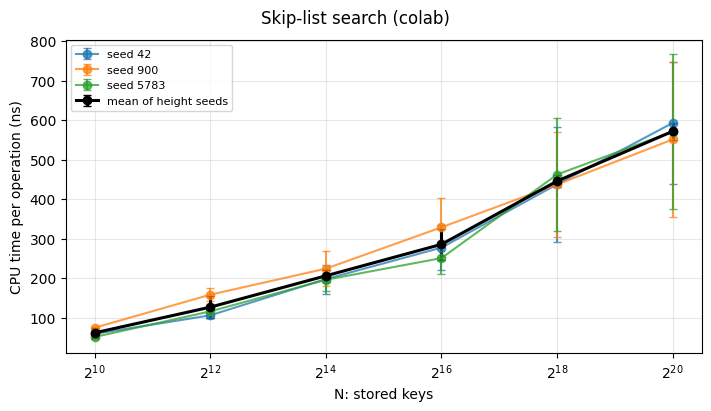

In [10]:
search_summary = search_times.groupby(["height_seed", "N"], as_index=False).agg(
    mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std")
)
search_summary.to_csv(csv_dir / "search_summary.csv", index=False)
search_mean = search_summary.groupby("N", as_index=False).agg(
    mean_ns=("mean_ns", "mean"), std_ns=("mean_ns", "std")
)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
for seed, group in search_summary.groupby("height_seed"):
    ax.errorbar(group["N"], group["mean_ns"], yerr=group["std_ns"], marker="o", capsize=3, alpha=0.75, label=f"seed {seed}")
ax.errorbar(search_mean["N"], search_mean["mean_ns"], yerr=search_mean["std_ns"], color="black", linewidth=2.2, marker="o", capsize=3, label="mean of height seeds")
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: stored keys")
ax.set_ylabel("CPU time per operation (ns)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.suptitle(f"Skip-list search ({RUN_LABEL})")
fig.savefig(figure_dir / "search.png", dpi=180)
fig.savefig(figure_dir / "search.pdf")
plt.show()
plt.close(fig)

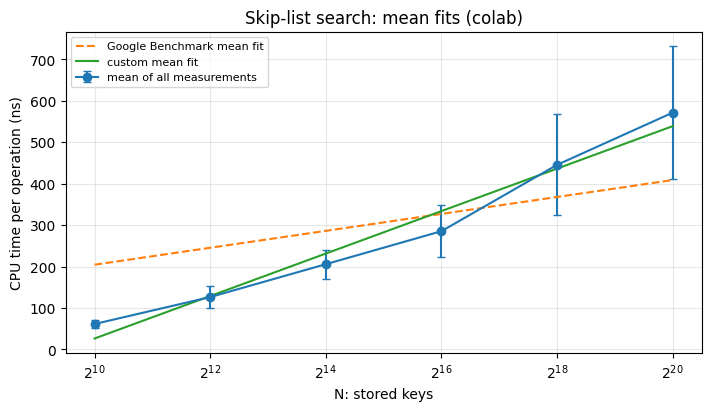

In [11]:
fit_mean = search_fit_comparison.agg({"google_a_ns": "mean", "custom_a_ns": "mean", "custom_b_ns": "mean"})
mean_measurements = search_times.groupby("N", as_index=False).agg(
    mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std")
)
sizes_for_fit = np.geomspace(min(SIZES), max(SIZES), 200)
x_for_fit = np.log2(sizes_for_fit)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
ax.errorbar(mean_measurements["N"], mean_measurements["mean_ns"], yerr=mean_measurements["std_ns"], marker="o", capsize=3, label="mean of all measurements")
ax.plot(sizes_for_fit, fit_mean["google_a_ns"] * x_for_fit, "--", label="Google Benchmark mean fit")
ax.plot(sizes_for_fit, fit_mean["custom_a_ns"] * x_for_fit + fit_mean["custom_b_ns"], label="custom mean fit")
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: stored keys")
ax.set_ylabel("CPU time per operation (ns)")
ax.set_title(f"Skip-list search: mean fits ({RUN_LABEL})")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.savefig(figure_dir / "search_fit_comparison.png", dpi=180)
fig.savefig(figure_dir / "search_fit_comparison.pdf")
plt.show()
plt.close(fig)

## Insert

Each iteration builds a fresh list of N even keys, then inserts **32 distinct absent odd keys** spread across the key range and shuffled using workload seed 17. The size grows from N to N+32. Construction, checking, and destruction are untimed; insertion allocations and height generation remain timed.

### Run and preserve raw data

This cell runs only insert and saves all repetitions, summaries, and complexity fits in `insertion.json`.

In [12]:
insert_file = json_dir / "insertion.json"
if RERUN_BENCHMARKS:
    subprocess.run([str(executable), "--benchmark_filter=^insertion/", "--benchmark_min_time=" + MIN_TIME, "--benchmark_out=" + str(insert_file), "--benchmark_out_format=json"], check=True)
elif not insert_file.is_file():
    raise FileNotFoundError("insertion.json is missing. Set RERUN_BENCHMARKS = True to create it.")
else:
    print("Reusing raw data:", insert_file)
insert_raw = json.loads(insert_file.read_text())
errors = [row for row in insert_raw["benchmarks"] if row.get("error_occurred")]
if errors: raise RuntimeError(errors)
print("Raw data:", insert_file)

Raw data: /tmp/skip_list_ps9s9sw_/skip_list/google_benchmark/JSON/colab/insertion.json


### Convert timings to time per operation

Keep the 54 individual timing records. Divide each iteration's CPU and elapsed time by **32** to obtain time per insert. The CSV retains both iteration and per-operation times.

In [13]:
insert_times = pd.DataFrame(row for row in insert_raw["benchmarks"]
                            if row.get("run_type") == "iteration")
assert len(insert_times) == len(SIZES) * len(HEIGHT_SEEDS) * REPETITIONS
assert insert_times["run_name"].str.startswith("insertion/").all()
assert insert_times["time_unit"].eq("ns").all()
assert insert_times["operations_per_iteration"].eq(32).all()
assert set(insert_times["N"]) == set(SIZES)
assert set(insert_times["height_seed"]) == set(HEIGHT_SEEDS)
assert insert_times.groupby(["height_seed", "N"]).size().eq(REPETITIONS).all()
assert not insert_times.duplicated(["height_seed", "N", "repetition_index"]).any()

insert_times["cpu_per_operation_ns"] = insert_times["cpu_time"] / 32
insert_times["real_per_operation_ns"] = insert_times["real_time"] / 32
insert_times["repetition"] = insert_times["repetition_index"] + 1
insert_times = insert_times.rename(columns={"cpu_time": "cpu_batch_ns", "real_time": "real_batch_ns"})
insert_times = insert_times[["N", "height_seed", "repetition", "iterations", "operations_per_iteration",
                               "cpu_batch_ns", "real_batch_ns", "cpu_per_operation_ns", "real_per_operation_ns"]]
insert_times = insert_times.astype({"N": int, "height_seed": int, "operations_per_iteration": int})
insert_times = insert_times.sort_values(["height_seed", "N", "repetition"])
insert_times.to_csv(csv_dir / "insertion.csv", index=False)
insert_times.head(6)

,N,height_seed,repetition,iterations,operations_per_iteration,cpu_batch_ns,real_batch_ns,cpu_per_operation_ns,real_per_operation_ns
0,1024,42,1,10,32,22811.1,25588.900007,712.846875,799.653125
1,1024,42,2,10,32,18868.9,19077.900004,589.653125,596.184375
2,1024,42,3,10,32,21335.7,21520.400003,666.740625,672.512500
3,4096,42,1,10,32,29340.3,29812.699961,916.884375,931.646874
4,4096,42,2,10,32,27702.4,27942.400015,865.700000,873.200000
5,4096,42,3,10,32,26661.5,26976.899983,833.171875,843.028124


### Google Benchmark fit: supplied logarithmic model

The C++ registration uses `Complexity(benchmark::oLogN)`. We supply the shape `t(N) = a * log2(N)`; Google Benchmark estimates a with **no intercept**. This is not automatic model selection.

The CPU coefficient is divided by **32**, matching the time per operation. Normalized RMS is multiplied by 100 to show a percentage, with no batch division. Rebuild and rerun the method to obtain JSON marked with the supplied model; old automatic-fit files are not relabelled.

In [14]:
assert insert_raw["context"].get("complexity_model") == "supplied log2(N), no intercept", "Rebuild and rerun this method: its JSON uses the previous fitting setup."
insert_fit_rows = []
for row in insert_raw["benchmarks"]:
    if row.get("aggregate_name") != "BigO":
        continue
    assert row["big_o"] == "lgN", "Expected the supplied logarithmic model"
    rms = next(r for r in insert_raw["benchmarks"]
               if r.get("aggregate_name") == "RMS" and r["run_name"] == row["run_name"])
    insert_fit_rows.append({
        "height_seed": int(re.search(r"seed_(\d+)", row["run_name"]).group(1)),
        "model": row["big_o"],
        "cpu_coefficient_per_operation_ns": row["cpu_coefficient"] / 32,
        "cpu_normalized_rms_percent": 100 * rms["rms"]
    })
insert_fits = pd.DataFrame(insert_fit_rows).sort_values("height_seed")
assert len(insert_fits) == len(HEIGHT_SEEDS)
assert set(insert_fits["height_seed"]) == set(HEIGHT_SEEDS)
insert_fits.to_csv(csv_dir / "insertion_complexity.csv", index=False)
insert_fits

,height_seed,model,cpu_coefficient_per_operation_ns,cpu_normalized_rms_percent
0,42,lgN,221.632557,50.223062
1,900,lgN,219.863188,53.485510
2,5783,lgN,220.253170,47.257605


### Custom fit: least squares with an intercept

Fit `t(N) = a * log2(N) + b` separately for each height seed using `np.linalg.lstsq`. The inputs are **all individual CPU timings per operation**, including all three repetitions at each N. Thus both fits use the same observations and least-squares objective.

Compare errors using `100 * sqrt(mean((measured - predicted)**2)) / mean(measured)`, the same normalized RMS definition used by Google Benchmark. The custom fit has an extra parameter, so a lower fitting error is expected and is not proof of logarithmic complexity. The intercept b can be negative; use the fit only within the measured range.

In [15]:
insert_custom_rows = []
for seed, group in insert_times.groupby("height_seed"):
    x = np.log2(group["N"].to_numpy(dtype=float))
    y = group["cpu_per_operation_ns"].to_numpy(dtype=float)
    design = np.column_stack((x, np.ones_like(x)))
    a, b = np.linalg.lstsq(design, y, rcond=None)[0]
    predicted = a * x + b
    rms_percent = 100 * np.sqrt(np.mean((y - predicted)**2)) / np.mean(y)
    insert_custom_rows.append({
        "height_seed": int(seed), "a_ns": a, "b_ns": b,
        "cpu_normalized_rms_percent": rms_percent
    })
insert_custom_fits = pd.DataFrame(insert_custom_rows).sort_values("height_seed")
insert_custom_fits.to_csv(csv_dir / "insertion_custom_complexity.csv", index=False)

insert_fit_comparison = insert_fits.rename(columns={
    "cpu_coefficient_per_operation_ns": "google_a_ns",
    "cpu_normalized_rms_percent": "google_rms_percent"
}).drop(columns="model").merge(
    insert_custom_fits.rename(columns={
        "a_ns": "custom_a_ns", "b_ns": "custom_b_ns",
        "cpu_normalized_rms_percent": "custom_rms_percent"
    }), on="height_seed", validate="one_to_one"
)
insert_fit_comparison.to_csv(csv_dir / "insertion_fit_comparison.csv", index=False)
insert_fit_comparison

,height_seed,google_a_ns,google_rms_percent,custom_a_ns,custom_b_ns,custom_rms_percent
0,42,221.632557,50.223062,621.793259,-6313.646627,18.924763
1,900,219.863188,53.485510,631.993199,-6502.495734,22.571473
2,5783,220.253170,47.257605,589.575476,-5827.085268,19.844722


### Plot

Each coloured line fixes one height seed. Points show mean CPU time over three repetitions and error bars show their sample standard deviation. The black line is the mean of the three seed means. No time/log plot is used here: the fitted models below make the scaling assumption explicit.

The fit-comparison figure uses one axis. It plots the mean timing data and the mean of the three Google Benchmark and custom-fit coefficients; dashed is Google Benchmark and solid is the custom fit.

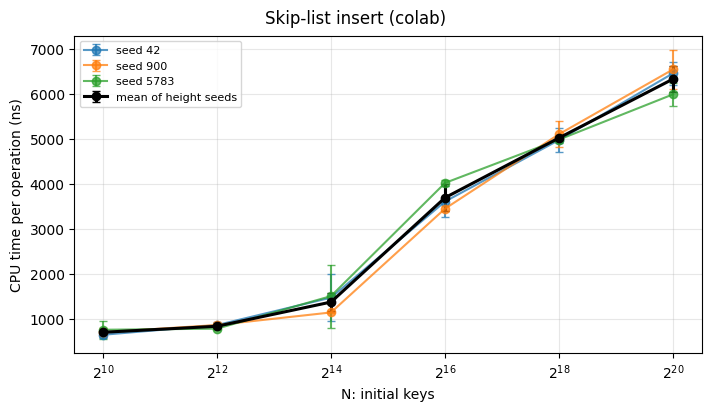

In [16]:
insert_summary = insert_times.groupby(["height_seed", "N"], as_index=False).agg(
    mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std")
)
insert_summary.to_csv(csv_dir / "insertion_summary.csv", index=False)
insert_mean = insert_summary.groupby("N", as_index=False).agg(
    mean_ns=("mean_ns", "mean"), std_ns=("mean_ns", "std")
)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
for seed, group in insert_summary.groupby("height_seed"):
    ax.errorbar(group["N"], group["mean_ns"], yerr=group["std_ns"], marker="o", capsize=3, alpha=0.75, label=f"seed {seed}")
ax.errorbar(insert_mean["N"], insert_mean["mean_ns"], yerr=insert_mean["std_ns"], color="black", linewidth=2.2, marker="o", capsize=3, label="mean of height seeds")
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: initial keys")
ax.set_ylabel("CPU time per operation (ns)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.suptitle(f"Skip-list insert ({RUN_LABEL})")
fig.savefig(figure_dir / "insertion.png", dpi=180)
fig.savefig(figure_dir / "insertion.pdf")
plt.show()
plt.close(fig)

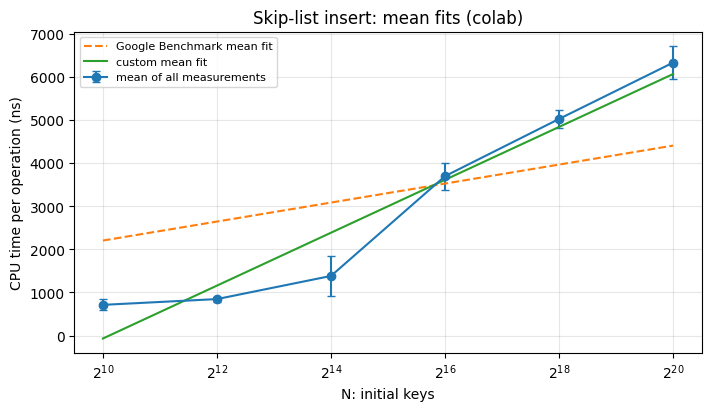

In [17]:
fit_mean = insert_fit_comparison.agg({"google_a_ns": "mean", "custom_a_ns": "mean", "custom_b_ns": "mean"})
mean_measurements = insert_times.groupby("N", as_index=False).agg(
    mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std")
)
sizes_for_fit = np.geomspace(min(SIZES), max(SIZES), 200)
x_for_fit = np.log2(sizes_for_fit)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
ax.errorbar(mean_measurements["N"], mean_measurements["mean_ns"], yerr=mean_measurements["std_ns"], marker="o", capsize=3, label="mean of all measurements")
ax.plot(sizes_for_fit, fit_mean["google_a_ns"] * x_for_fit, "--", label="Google Benchmark mean fit")
ax.plot(sizes_for_fit, fit_mean["custom_a_ns"] * x_for_fit + fit_mean["custom_b_ns"], label="custom mean fit")
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: initial keys")
ax.set_ylabel("CPU time per operation (ns)")
ax.set_title(f"Skip-list insert: mean fits ({RUN_LABEL})")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.savefig(figure_dir / "insertion_fit_comparison.png", dpi=180)
fig.savefig(figure_dir / "insertion_fit_comparison.pdf")
plt.show()
plt.close(fig)

## Ordered union

The fresh inputs have **N/2 keys each**: A contains the even keys from 0 through N-2, and B contains the even keys from N through 2*N-2. N is their combined size. Both lists share one handler and use successive random draws. One union is timed per iteration. Input construction, validation, and destruction of outputs/consumed objects are untimed; work inside the union remains timed.

### Run and preserve raw data

This cell runs only ordered union and saves all repetitions, summaries, and complexity fits in `ordered_union.json`.

In [18]:
union_file = json_dir / "ordered_union.json"
if RERUN_BENCHMARKS:
    subprocess.run([str(executable), "--benchmark_filter=^ordered_union/", "--benchmark_min_time=" + MIN_TIME, "--benchmark_out=" + str(union_file), "--benchmark_out_format=json"], check=True)
elif not union_file.is_file():
    raise FileNotFoundError("ordered_union.json is missing. Set RERUN_BENCHMARKS = True to create it.")
else:
    print("Reusing raw data:", union_file)
union_raw = json.loads(union_file.read_text())
errors = [row for row in union_raw["benchmarks"] if row.get("error_occurred")]
if errors: raise RuntimeError(errors)
print("Raw data:", union_file)

Raw data: /tmp/skip_list_ps9s9sw_/skip_list/google_benchmark/JSON/colab/ordered_union.json


### Convert timings to time per operation

Keep the 54 individual timing records. Divide each iteration's CPU and elapsed time by **1** to obtain time per ordered union. The CSV retains both iteration and per-operation times.

In [19]:
union_times = pd.DataFrame(row for row in union_raw["benchmarks"]
                            if row.get("run_type") == "iteration")
assert len(union_times) == len(SIZES) * len(HEIGHT_SEEDS) * REPETITIONS
assert union_times["run_name"].str.startswith("ordered_union/").all()
assert union_times["time_unit"].eq("ns").all()
assert union_times["operations_per_iteration"].eq(1).all()
assert set(union_times["N"]) == set(SIZES)
assert set(union_times["height_seed"]) == set(HEIGHT_SEEDS)
assert union_times.groupby(["height_seed", "N"]).size().eq(REPETITIONS).all()
assert not union_times.duplicated(["height_seed", "N", "repetition_index"]).any()

union_times["cpu_per_operation_ns"] = union_times["cpu_time"] / 1
union_times["real_per_operation_ns"] = union_times["real_time"] / 1
union_times["repetition"] = union_times["repetition_index"] + 1
union_times = union_times.rename(columns={"cpu_time": "cpu_batch_ns", "real_time": "real_batch_ns"})
union_times = union_times[["N", "height_seed", "repetition", "iterations", "operations_per_iteration",
                               "cpu_batch_ns", "real_batch_ns", "cpu_per_operation_ns", "real_per_operation_ns"]]
union_times = union_times.astype({"N": int, "height_seed": int, "operations_per_iteration": int})
union_times = union_times.sort_values(["height_seed", "N", "repetition"])
union_times.to_csv(csv_dir / "ordered_union.csv", index=False)
union_times.head(6)

,N,height_seed,repetition,iterations,operations_per_iteration,cpu_batch_ns,real_batch_ns,cpu_per_operation_ns,real_per_operation_ns
0,1024,42,1,10,1,2638.7,3322.999987,2638.7,3322.999987
1,1024,42,2,10,1,1913.2,2216.300049,1913.2,2216.300049
2,1024,42,3,10,1,2064.4,2436.099999,2064.4,2436.099999
3,4096,42,1,10,1,2593.3,3298.400009,2593.3,3298.400009
4,4096,42,2,10,1,2214.2,2611.300044,2214.2,2611.300044
5,4096,42,3,10,1,2138.1,2502.899986,2138.1,2502.899986


### Google Benchmark fit: supplied logarithmic model

The C++ registration uses `Complexity(benchmark::oLogN)`. We supply the shape `t(N) = a * log2(N)`; Google Benchmark estimates a with **no intercept**. This is not automatic model selection.

The CPU coefficient is divided by **1**, matching the time per operation. Normalized RMS is multiplied by 100 to show a percentage, with no batch division. Rebuild and rerun the method to obtain JSON marked with the supplied model; old automatic-fit files are not relabelled.

In [20]:
assert union_raw["context"].get("complexity_model") == "supplied log2(N), no intercept", "Rebuild and rerun this method: its JSON uses the previous fitting setup."
union_fit_rows = []
for row in union_raw["benchmarks"]:
    if row.get("aggregate_name") != "BigO":
        continue
    assert row["big_o"] == "lgN", "Expected the supplied logarithmic model"
    rms = next(r for r in union_raw["benchmarks"]
               if r.get("aggregate_name") == "RMS" and r["run_name"] == row["run_name"])
    union_fit_rows.append({
        "height_seed": int(re.search(r"seed_(\d+)", row["run_name"]).group(1)),
        "model": row["big_o"],
        "cpu_coefficient_per_operation_ns": row["cpu_coefficient"] / 1,
        "cpu_normalized_rms_percent": 100 * rms["rms"]
    })
union_fits = pd.DataFrame(union_fit_rows).sort_values("height_seed")
assert len(union_fits) == len(HEIGHT_SEEDS)
assert set(union_fits["height_seed"]) == set(HEIGHT_SEEDS)
union_fits.to_csv(csv_dir / "ordered_union_complexity.csv", index=False)
union_fits

,height_seed,model,cpu_coefficient_per_operation_ns,cpu_normalized_rms_percent
0,42,lgN,601.163146,43.908202
1,900,lgN,587.265962,41.781541
2,5783,lgN,568.912864,38.339990


### Custom fit: least squares with an intercept

Fit `t(N) = a * log2(N) + b` separately for each height seed using `np.linalg.lstsq`. The inputs are **all individual CPU timings per operation**, including all three repetitions at each N. Thus both fits use the same observations and least-squares objective.

Compare errors using `100 * sqrt(mean((measured - predicted)**2)) / mean(measured)`, the same normalized RMS definition used by Google Benchmark. The custom fit has an extra parameter, so a lower fitting error is expected and is not proof of logarithmic complexity. The intercept b can be negative; use the fit only within the measured range.

In [21]:
union_custom_rows = []
for seed, group in union_times.groupby("height_seed"):
    x = np.log2(group["N"].to_numpy(dtype=float))
    y = group["cpu_per_operation_ns"].to_numpy(dtype=float)
    design = np.column_stack((x, np.ones_like(x)))
    a, b = np.linalg.lstsq(design, y, rcond=None)[0]
    predicted = a * x + b
    rms_percent = 100 * np.sqrt(np.mean((y - predicted)**2)) / np.mean(y)
    union_custom_rows.append({
        "height_seed": int(seed), "a_ns": a, "b_ns": b,
        "cpu_normalized_rms_percent": rms_percent
    })
union_custom_fits = pd.DataFrame(union_custom_rows).sort_values("height_seed")
union_custom_fits.to_csv(csv_dir / "ordered_union_custom_complexity.csv", index=False)

union_fit_comparison = union_fits.rename(columns={
    "cpu_coefficient_per_operation_ns": "google_a_ns",
    "cpu_normalized_rms_percent": "google_rms_percent"
}).drop(columns="model").merge(
    union_custom_fits.rename(columns={
        "a_ns": "custom_a_ns", "b_ns": "custom_b_ns",
        "cpu_normalized_rms_percent": "custom_rms_percent"
    }), on="height_seed", validate="one_to_one"
)
union_fit_comparison.to_csv(csv_dir / "ordered_union_fit_comparison.csv", index=False)
union_fit_comparison

,height_seed,google_a_ns,google_rms_percent,custom_a_ns,custom_b_ns,custom_rms_percent
0,42,601.163146,43.908202,1552.466667,-15009.455555,17.524375
1,900,587.265962,41.781541,1473.488095,-13982.615874,16.847446
2,5783,568.912864,38.339990,1367.196667,-12595.144445,14.865268


### Plot

Each coloured line fixes one height seed. Points show mean CPU time over three repetitions and error bars show their sample standard deviation. The black line is the mean of the three seed means. No time/log plot is used here: the fitted models below make the scaling assumption explicit.

The fit-comparison figure uses one axis. It plots the mean timing data and the mean of the three Google Benchmark and custom-fit coefficients; dashed is Google Benchmark and solid is the custom fit.

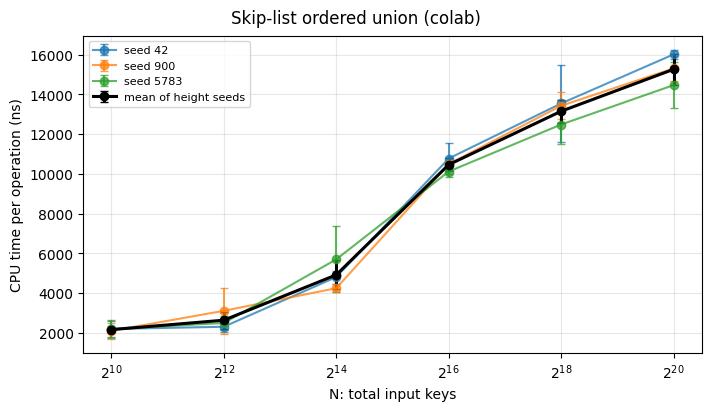

In [22]:
union_summary = union_times.groupby(["height_seed", "N"], as_index=False).agg(
    mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std")
)
union_summary.to_csv(csv_dir / "ordered_union_summary.csv", index=False)
union_mean = union_summary.groupby("N", as_index=False).agg(
    mean_ns=("mean_ns", "mean"), std_ns=("mean_ns", "std")
)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
for seed, group in union_summary.groupby("height_seed"):
    ax.errorbar(group["N"], group["mean_ns"], yerr=group["std_ns"], marker="o", capsize=3, alpha=0.75, label=f"seed {seed}")
ax.errorbar(union_mean["N"], union_mean["mean_ns"], yerr=union_mean["std_ns"], color="black", linewidth=2.2, marker="o", capsize=3, label="mean of height seeds")
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: total input keys")
ax.set_ylabel("CPU time per operation (ns)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.suptitle(f"Skip-list ordered union ({RUN_LABEL})")
fig.savefig(figure_dir / "ordered_union.png", dpi=180)
fig.savefig(figure_dir / "ordered_union.pdf")
plt.show()
plt.close(fig)

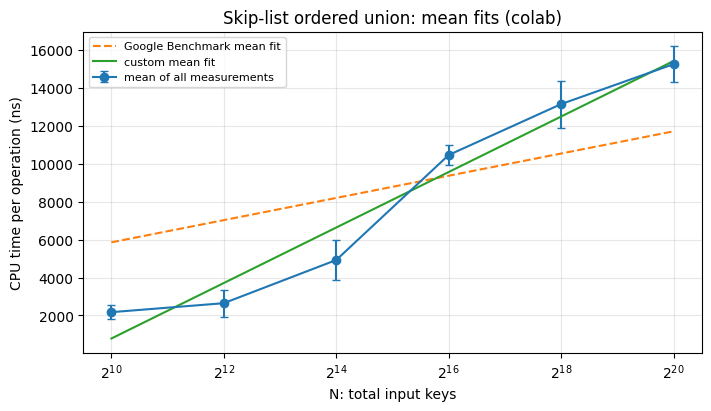

In [23]:
fit_mean = union_fit_comparison.agg({"google_a_ns": "mean", "custom_a_ns": "mean", "custom_b_ns": "mean"})
mean_measurements = union_times.groupby("N", as_index=False).agg(
    mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std")
)
sizes_for_fit = np.geomspace(min(SIZES), max(SIZES), 200)
x_for_fit = np.log2(sizes_for_fit)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
ax.errorbar(mean_measurements["N"], mean_measurements["mean_ns"], yerr=mean_measurements["std_ns"], marker="o", capsize=3, label="mean of all measurements")
ax.plot(sizes_for_fit, fit_mean["google_a_ns"] * x_for_fit, "--", label="Google Benchmark mean fit")
ax.plot(sizes_for_fit, fit_mean["custom_a_ns"] * x_for_fit + fit_mean["custom_b_ns"], label="custom mean fit")
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: total input keys")
ax.set_ylabel("CPU time per operation (ns)")
ax.set_title(f"Skip-list ordered union: mean fits ({RUN_LABEL})")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.savefig(figure_dir / "ordered_union_fit_comparison.png", dpi=180)
fig.savefig(figure_dir / "ordered_union_fit_comparison.pdf")
plt.show()
plt.close(fig)

## Split

Each iteration starts with a fresh N-key list of even keys. The absent pivot **N-1** gives two outputs of N/2 keys each. One split is timed per iteration. The pivot is determined in advance. Construction, validation, and output destruction are untimed; header handling inside the split remains timed.

### Run and preserve raw data

This cell runs only split and saves all repetitions, summaries, and complexity fits in `split.json`.

In [24]:
split_file = json_dir / "split.json"
if RERUN_BENCHMARKS:
    subprocess.run([str(executable), "--benchmark_filter=^split/", "--benchmark_min_time=" + MIN_TIME, "--benchmark_out=" + str(split_file), "--benchmark_out_format=json"], check=True)
elif not split_file.is_file():
    raise FileNotFoundError("split.json is missing. Set RERUN_BENCHMARKS = True to create it.")
else:
    print("Reusing raw data:", split_file)
split_raw = json.loads(split_file.read_text())
errors = [row for row in split_raw["benchmarks"] if row.get("error_occurred")]
if errors: raise RuntimeError(errors)
print("Raw data:", split_file)

Raw data: /tmp/skip_list_ps9s9sw_/skip_list/google_benchmark/JSON/colab/split.json


### Convert timings to time per operation

Keep the 54 individual timing records. Divide each iteration's CPU and elapsed time by **1** to obtain time per split. The CSV retains both iteration and per-operation times.

In [25]:
split_times = pd.DataFrame(row for row in split_raw["benchmarks"]
                            if row.get("run_type") == "iteration")
assert len(split_times) == len(SIZES) * len(HEIGHT_SEEDS) * REPETITIONS
assert split_times["run_name"].str.startswith("split/").all()
assert split_times["time_unit"].eq("ns").all()
assert split_times["operations_per_iteration"].eq(1).all()
assert set(split_times["N"]) == set(SIZES)
assert set(split_times["height_seed"]) == set(HEIGHT_SEEDS)
assert split_times.groupby(["height_seed", "N"]).size().eq(REPETITIONS).all()
assert not split_times.duplicated(["height_seed", "N", "repetition_index"]).any()

split_times["cpu_per_operation_ns"] = split_times["cpu_time"] / 1
split_times["real_per_operation_ns"] = split_times["real_time"] / 1
split_times["repetition"] = split_times["repetition_index"] + 1
split_times = split_times.rename(columns={"cpu_time": "cpu_batch_ns", "real_time": "real_batch_ns"})
split_times = split_times[["N", "height_seed", "repetition", "iterations", "operations_per_iteration",
                               "cpu_batch_ns", "real_batch_ns", "cpu_per_operation_ns", "real_per_operation_ns"]]
split_times = split_times.astype({"N": int, "height_seed": int, "operations_per_iteration": int})
split_times = split_times.sort_values(["height_seed", "N", "repetition"])
split_times.to_csv(csv_dir / "split.csv", index=False)
split_times.head(6)

,N,height_seed,repetition,iterations,operations_per_iteration,cpu_batch_ns,real_batch_ns,cpu_per_operation_ns,real_per_operation_ns
0,1024,42,1,10,1,3934.1,5120.600008,3934.1,5120.600008
1,1024,42,2,10,1,3242.5,4008.600001,3242.5,4008.600001
2,1024,42,3,10,1,3300.9,4033.599998,3300.9,4033.599998
3,4096,42,1,10,1,4137.3,5521.200012,4137.3,5521.200012
4,4096,42,2,10,1,2537.0,3220.300016,2537.0,3220.300016
5,4096,42,3,10,1,4426.7,4953.899986,4426.7,4953.899986


### Google Benchmark fit: supplied logarithmic model

The C++ registration uses `Complexity(benchmark::oLogN)`. We supply the shape `t(N) = a * log2(N)`; Google Benchmark estimates a with **no intercept**. This is not automatic model selection.

The CPU coefficient is divided by **1**, matching the time per operation. Normalized RMS is multiplied by 100 to show a percentage, with no batch division. Rebuild and rerun the method to obtain JSON marked with the supplied model; old automatic-fit files are not relabelled.

In [26]:
assert split_raw["context"].get("complexity_model") == "supplied log2(N), no intercept", "Rebuild and rerun this method: its JSON uses the previous fitting setup."
split_fit_rows = []
for row in split_raw["benchmarks"]:
    if row.get("aggregate_name") != "BigO":
        continue
    assert row["big_o"] == "lgN", "Expected the supplied logarithmic model"
    rms = next(r for r in split_raw["benchmarks"]
               if r.get("aggregate_name") == "RMS" and r["run_name"] == row["run_name"])
    split_fit_rows.append({
        "height_seed": int(re.search(r"seed_(\d+)", row["run_name"]).group(1)),
        "model": row["big_o"],
        "cpu_coefficient_per_operation_ns": row["cpu_coefficient"] / 1,
        "cpu_normalized_rms_percent": 100 * rms["rms"]
    })
split_fits = pd.DataFrame(split_fit_rows).sort_values("height_seed")
assert len(split_fits) == len(HEIGHT_SEEDS)
assert set(split_fits["height_seed"]) == set(HEIGHT_SEEDS)
split_fits.to_csv(csv_dir / "split_complexity.csv", index=False)
split_fits

,height_seed,model,cpu_coefficient_per_operation_ns,cpu_normalized_rms_percent
0,42,lgN,788.490000,40.929354
1,900,lgN,781.686056,53.629673
2,5783,lgN,698.048451,53.458554


### Custom fit: least squares with an intercept

Fit `t(N) = a * log2(N) + b` separately for each height seed using `np.linalg.lstsq`. The inputs are **all individual CPU timings per operation**, including all three repetitions at each N. Thus both fits use the same observations and least-squares objective.

Compare errors using `100 * sqrt(mean((measured - predicted)**2)) / mean(measured)`, the same normalized RMS definition used by Google Benchmark. The custom fit has an extra parameter, so a lower fitting error is expected and is not proof of logarithmic complexity. The intercept b can be negative; use the fit only within the measured range.

In [27]:
split_custom_rows = []
for seed, group in split_times.groupby("height_seed"):
    x = np.log2(group["N"].to_numpy(dtype=float))
    y = group["cpu_per_operation_ns"].to_numpy(dtype=float)
    design = np.column_stack((x, np.ones_like(x)))
    a, b = np.linalg.lstsq(design, y, rcond=None)[0]
    predicted = a * x + b
    rms_percent = 100 * np.sqrt(np.mean((y - predicted)**2)) / np.mean(y)
    split_custom_rows.append({
        "height_seed": int(seed), "a_ns": a, "b_ns": b,
        "cpu_normalized_rms_percent": rms_percent
    })
split_custom_fits = pd.DataFrame(split_custom_rows).sort_values("height_seed")
split_custom_fits.to_csv(csv_dir / "split_custom_complexity.csv", index=False)

split_fit_comparison = split_fits.rename(columns={
    "cpu_coefficient_per_operation_ns": "google_a_ns",
    "cpu_normalized_rms_percent": "google_rms_percent"
}).drop(columns="model").merge(
    split_custom_fits.rename(columns={
        "a_ns": "custom_a_ns", "b_ns": "custom_b_ns",
        "cpu_normalized_rms_percent": "custom_rms_percent"
    }), on="height_seed", validate="one_to_one"
)
split_fit_comparison.to_csv(csv_dir / "split_fit_comparison.csv", index=False)
split_fit_comparison

,height_seed,google_a_ns,google_rms_percent,custom_a_ns,custom_b_ns,custom_rms_percent
0,42,788.490000,40.929354,1914.304286,-17762.847619,19.453008
1,900,781.686056,53.629673,2286.110000,-23736.466670,19.575767
2,5783,698.048451,53.458554,2024.204286,-20923.792061,20.870977


### Plot

Each coloured line fixes one height seed. Points show mean CPU time over three repetitions and error bars show their sample standard deviation. The black line is the mean of the three seed means. No time/log plot is used here: the fitted models below make the scaling assumption explicit.

The fit-comparison figure uses one axis. It plots the mean timing data and the mean of the three Google Benchmark and custom-fit coefficients; dashed is Google Benchmark and solid is the custom fit.

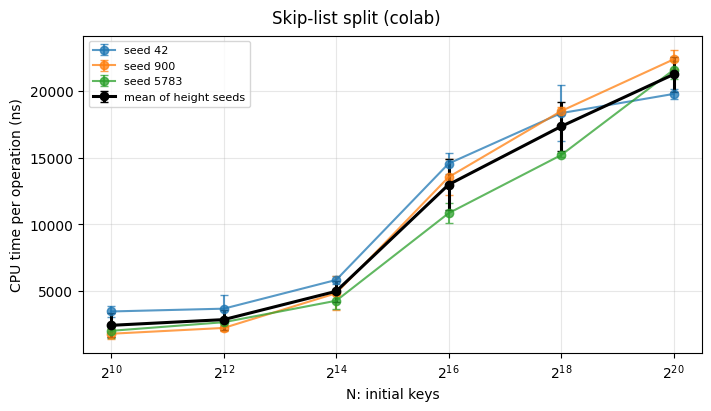

In [28]:
split_summary = split_times.groupby(["height_seed", "N"], as_index=False).agg(
    mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std")
)
split_summary.to_csv(csv_dir / "split_summary.csv", index=False)
split_mean = split_summary.groupby("N", as_index=False).agg(
    mean_ns=("mean_ns", "mean"), std_ns=("mean_ns", "std")
)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
for seed, group in split_summary.groupby("height_seed"):
    ax.errorbar(group["N"], group["mean_ns"], yerr=group["std_ns"], marker="o", capsize=3, alpha=0.75, label=f"seed {seed}")
ax.errorbar(split_mean["N"], split_mean["mean_ns"], yerr=split_mean["std_ns"], color="black", linewidth=2.2, marker="o", capsize=3, label="mean of height seeds")
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: initial keys")
ax.set_ylabel("CPU time per operation (ns)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.suptitle(f"Skip-list split ({RUN_LABEL})")
fig.savefig(figure_dir / "split.png", dpi=180)
fig.savefig(figure_dir / "split.pdf")
plt.show()
plt.close(fig)

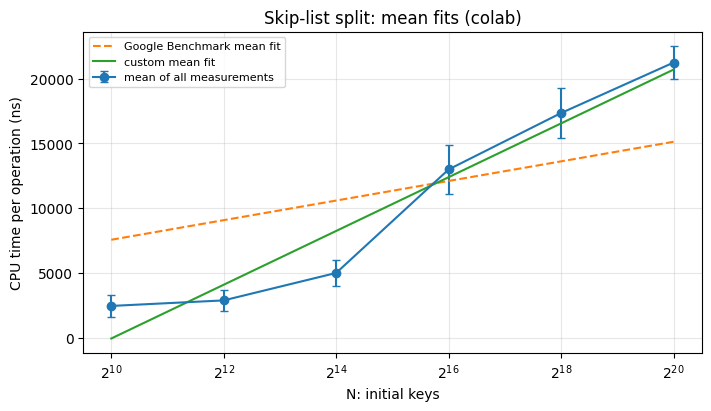

In [29]:
fit_mean = split_fit_comparison.agg({"google_a_ns": "mean", "custom_a_ns": "mean", "custom_b_ns": "mean"})
mean_measurements = split_times.groupby("N", as_index=False).agg(
    mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std")
)
sizes_for_fit = np.geomspace(min(SIZES), max(SIZES), 200)
x_for_fit = np.log2(sizes_for_fit)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
ax.errorbar(mean_measurements["N"], mean_measurements["mean_ns"], yerr=mean_measurements["std_ns"], marker="o", capsize=3, label="mean of all measurements")
ax.plot(sizes_for_fit, fit_mean["google_a_ns"] * x_for_fit, "--", label="Google Benchmark mean fit")
ax.plot(sizes_for_fit, fit_mean["custom_a_ns"] * x_for_fit + fit_mean["custom_b_ns"], label="custom mean fit")
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: initial keys")
ax.set_ylabel("CPU time per operation (ns)")
ax.set_title(f"Skip-list split: mean fits ({RUN_LABEL})")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.savefig(figure_dir / "split_fit_comparison.png", dpi=180)
fig.savefig(figure_dir / "split_fit_comparison.pdf")
plt.show()
plt.close(fig)

### Rebuilding split comparison: run and preserve raw data

Run the structural Split cells above first. Both variants use the same N even keys, insertion order, height seeds and pivot N-1. The rebuilding method inserts the keys into fresh outputs, draws fresh heights from the shared handler, and frees the consumed input nodes **inside the timed operation**. Input construction, validation and output destruction remain untimed.

The expected costs are O(log(N+2)) for structural split and O(N log(N+2)) for this rebuilding baseline using ordinary insertions, with expected O(N) disposal work. Timing fits alone do not prove either bound.

First run the rebuilding correctness checks in a separate process. They verify consumption, fresh heights, independence and input reuse. A failure stops this cell before collecting misleading timings. The benchmark also checks that rebuilding advances the height generator.

The same ten iterations and three repetitions are used for both variants. This can take several minutes at the largest sizes. Raw baseline data is saved separately in `split_rebuild.json`; the earlier structural data stays in `split.json`.

In [30]:
rebuild_file = json_dir / "split_rebuild.json"
if RERUN_BENCHMARKS:
    subprocess.run([str(build_dir / "skip_list_test"), "--split-rebuild", "--seeds", ",".join(str(seed) for seed in HEIGHT_SEEDS)], check=True)
    subprocess.run([str(executable), "--benchmark_filter=^split_rebuild/", "--benchmark_min_time=" + MIN_TIME, "--benchmark_out=" + str(rebuild_file), "--benchmark_out_format=json"], check=True)
elif not rebuild_file.is_file():
    raise FileNotFoundError("split_rebuild.json is missing. Set RERUN_BENCHMARKS = True to create it.")
else:
    print("Reusing raw data:", rebuild_file)
rebuild_raw = json.loads(rebuild_file.read_text())
errors = [row for row in rebuild_raw["benchmarks"] if row.get("error_occurred")]
if errors: raise RuntimeError(errors)
print("Raw data:", rebuild_file)

Raw data: /tmp/skip_list_ps9s9sw_/skip_list/google_benchmark/JSON/colab/split_rebuild.json


### Convert rebuilding timings to time per operation

One iteration performs one rebuilding split, so B=1. Keep all 54 timing records and save them in `split_rebuild.csv`.

In [31]:
rebuild_times = pd.DataFrame(row for row in rebuild_raw["benchmarks"]
                            if row.get("run_type") == "iteration")
assert len(rebuild_times) == len(SIZES) * len(HEIGHT_SEEDS) * REPETITIONS
assert rebuild_times["run_name"].str.startswith("split_rebuild/").all()
assert rebuild_times["time_unit"].eq("ns").all()
assert rebuild_times["operations_per_iteration"].eq(1).all()
assert set(rebuild_times["N"]) == set(SIZES)
assert set(rebuild_times["height_seed"]) == set(HEIGHT_SEEDS)
assert rebuild_times.groupby(["height_seed", "N"]).size().eq(REPETITIONS).all()
assert not rebuild_times.duplicated(["height_seed", "N", "repetition_index"]).any()

rebuild_times["cpu_per_operation_ns"] = rebuild_times["cpu_time"] / 1
rebuild_times["real_per_operation_ns"] = rebuild_times["real_time"] / 1
rebuild_times["repetition"] = rebuild_times["repetition_index"] + 1
rebuild_times = rebuild_times.rename(columns={"cpu_time": "cpu_batch_ns", "real_time": "real_batch_ns"})
rebuild_times = rebuild_times[["N", "height_seed", "repetition", "iterations", "operations_per_iteration",
                               "cpu_batch_ns", "real_batch_ns", "cpu_per_operation_ns", "real_per_operation_ns"]]
rebuild_times = rebuild_times.astype({"N": int, "height_seed": int, "operations_per_iteration": int})
rebuild_times = rebuild_times.sort_values(["height_seed", "N", "repetition"])
rebuild_times.to_csv(csv_dir / "split_rebuild.csv", index=False)
rebuild_times.head(6)

,N,height_seed,repetition,iterations,operations_per_iteration,cpu_batch_ns,real_batch_ns,cpu_per_operation_ns,real_per_operation_ns
0,1024,42,1,10,1,542063.3,5.473795e+05,542063.3,5.473795e+05
1,1024,42,2,10,1,457920.1,4.579654e+05,457920.1,4.579654e+05
2,1024,42,3,10,1,408993.0,4.091261e+05,408993.0,4.091261e+05
3,4096,42,1,10,1,1755203.2,1.757131e+06,1755203.2,1.757131e+06
4,4096,42,2,10,1,1763730.3,1.763971e+06,1763730.3,1.763971e+06
5,4096,42,3,10,1,1752841.8,1.753106e+06,1752841.8,1.753106e+06


### Google Benchmark fit: supplied \(N\log N\) model

The rebuilding C++ registration uses `Complexity(benchmark::oNLogN)`. We supply the shape `t(N) = a * N * log2(N)`; Google Benchmark estimates a with **no intercept**. This is not automatic model selection.

One rebuilding split is timed per iteration, so B=1 and the CPU coefficient needs no batch division. Normalized RMS is multiplied by 100 to show a percentage. Rebuild and rerun this method to obtain JSON marked with the supplied \(N\log N\) model; earlier linear-fit files are not relabelled. The supplied model is a timing hypothesis, not a proof of asymptotic complexity.

In [32]:
assert rebuild_raw["context"].get("split_rebuild_complexity_model") == "supplied N log2(N), no intercept", "Rebuild and rerun this method: its JSON uses the previous fitting setup."
rebuild_fit_rows = []
for row in rebuild_raw["benchmarks"]:
    if row.get("aggregate_name") != "BigO":
        continue
    assert row["big_o"] == "NlgN", "Expected the supplied N log N model"
    rms = next(r for r in rebuild_raw["benchmarks"]
               if r.get("aggregate_name") == "RMS" and r["run_name"] == row["run_name"])
    rebuild_fit_rows.append({
        "height_seed": int(re.search(r"seed_(\d+)", row["run_name"]).group(1)),
        "model": row["big_o"],
        "cpu_coefficient_per_operation_ns": row["cpu_coefficient"] / 1,
        "cpu_normalized_rms_percent": 100 * rms["rms"]
    })
rebuild_fits = pd.DataFrame(rebuild_fit_rows).sort_values("height_seed")
assert len(rebuild_fits) == len(HEIGHT_SEEDS)
assert set(rebuild_fits["height_seed"]) == set(HEIGHT_SEEDS)
rebuild_fits.to_csv(csv_dir / "split_rebuild_complexity.csv", index=False)
rebuild_fits

,height_seed,model,cpu_coefficient_per_operation_ns,cpu_normalized_rms_percent
0,42,NlgN,60.385609,15.83625
1,900,NlgN,57.673440,11.50309
2,5783,NlgN,57.278913,9.54796


### Custom fit: least squares with an intercept

Fit `t(N) = a * N * log2(N) + b` separately for each height seed using `np.linalg.lstsq`. The inputs are **all individual CPU timings per operation**, including all three repetitions at each N. Thus both fits use the same observations and least-squares objective.

Compare errors using `100 * sqrt(mean((measured - predicted)**2)) / mean(measured)`, the same normalized RMS definition used by Google Benchmark. The custom fit has an extra parameter, so a lower fitting error is expected and is not proof of asymptotic complexity. The intercept b can be negative; use the fit only within the measured range.

In [33]:
rebuild_custom_rows = []
for seed, group in rebuild_times.groupby("height_seed"):
    n = group["N"].to_numpy(dtype=float)
    x = n * np.log2(n)
    y = group["cpu_per_operation_ns"].to_numpy(dtype=float)
    design = np.column_stack((x, np.ones_like(x)))
    a, b = np.linalg.lstsq(design, y, rcond=None)[0]
    predicted = a * x + b
    rms_percent = 100 * np.sqrt(np.mean((y - predicted)**2)) / np.mean(y)
    rebuild_custom_rows.append({
        "height_seed": int(seed), "a_ns": a, "b_ns": b,
        "cpu_normalized_rms_percent": rms_percent
    })
rebuild_custom_fits = pd.DataFrame(rebuild_custom_rows).sort_values("height_seed")
rebuild_custom_fits.to_csv(csv_dir / "split_rebuild_custom_complexity.csv", index=False)

rebuild_fit_comparison = rebuild_fits.rename(columns={
    "cpu_coefficient_per_operation_ns": "google_a_ns",
    "cpu_normalized_rms_percent": "google_rms_percent"
}).drop(columns="model").merge(
    rebuild_custom_fits.rename(columns={
        "a_ns": "custom_a_ns", "b_ns": "custom_b_ns",
        "cpu_normalized_rms_percent": "custom_rms_percent"
    }), on="height_seed", validate="one_to_one"
)
rebuild_fit_comparison.to_csv(csv_dir / "split_rebuild_fit_comparison.csv", index=False)
rebuild_fit_comparison

,height_seed,google_a_ns,google_rms_percent,custom_a_ns,custom_b_ns,custom_rms_percent
0,42,60.385609,15.83625,60.549698,-2.812328e+06,15.810967
1,900,57.673440,11.50309,57.797852,-2.132291e+06,11.481220
2,5783,57.278913,9.54796,57.253088,4.426076e+05,9.546826


### Plot structural versus rebuilding split

Lines use the mean CPU time over three repetitions; error bars show sample standard deviation. Solid lines are structural split and dashed lines are rebuilding split. The left panel uses logarithmic time to show both methods. The right panel shows rebuilding time divided by structural time, matching N and height seed. A ratio above one means rebuilding took longer. These ratios are descriptive, not confidence intervals.

Use results from the same machine and run label. Short structural timings remain sensitive to measurement overhead and noise. The comparison adds 54 timing records and three Google Benchmark fits and three custom fits.


The following fit-comparison figure shows individual measurements and both fitted curves, with one panel per height seed. Dashed lines show Google Benchmark's supplied model `a * N * log2(N)`; solid lines show the custom model `a * N * log2(N) + b`.

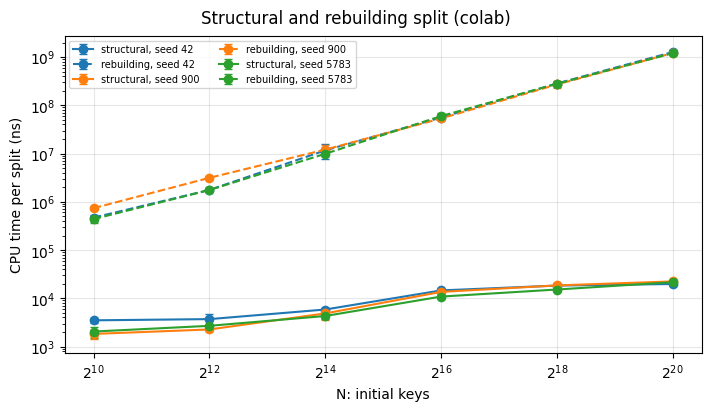

In [34]:
rebuild_summary = rebuild_times.groupby(["height_seed", "N"], as_index=False).agg(mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std"))
rebuild_summary.to_csv(csv_dir / "split_rebuild_summary.csv", index=False)
comparison = split_summary.merge(rebuild_summary, on=["height_seed", "N"], suffixes=("_structural", "_rebuild"), validate="one_to_one")
comparison.to_csv(csv_dir / "split_comparison.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
for i, (seed, group) in enumerate(comparison.groupby("height_seed")):
    color = f"C{i}"
    ax.errorbar(group["N"], group["mean_ns_structural"], yerr=group["std_ns_structural"], marker="o", linestyle="-", color=color, capsize=3, label=f"structural, seed {seed}")
    ax.errorbar(group["N"], group["mean_ns_rebuild"], yerr=group["std_ns_rebuild"], marker="o", linestyle="--", color=color, capsize=3, label=f"rebuilding, seed {seed}")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: initial keys"); ax.set_ylabel("CPU time per split (ns)")
ax.grid(True, alpha=0.3); ax.legend(fontsize=7, ncol=2)
fig.suptitle(f"Structural and rebuilding split ({RUN_LABEL})")
fig.savefig(figure_dir / "split_comparison.png", dpi=180)
fig.savefig(figure_dir / "split_comparison.pdf")
plt.show(); plt.close(fig)

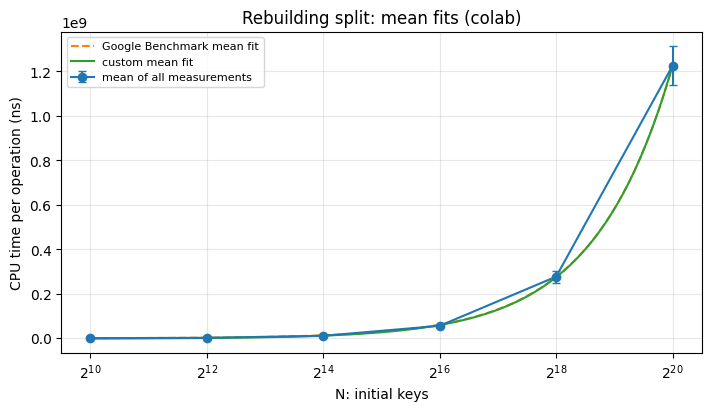

In [35]:
fit_mean = rebuild_fit_comparison.agg({"google_a_ns": "mean", "custom_a_ns": "mean", "custom_b_ns": "mean"})
mean_measurements = rebuild_times.groupby("N", as_index=False).agg(
    mean_ns=("cpu_per_operation_ns", "mean"), std_ns=("cpu_per_operation_ns", "std")
)
sizes_for_fit = np.geomspace(min(SIZES), max(SIZES), 200)
x_for_fit = sizes_for_fit * np.log2(sizes_for_fit)
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
ax.errorbar(mean_measurements["N"], mean_measurements["mean_ns"], yerr=mean_measurements["std_ns"], marker="o", capsize=3, label="mean of all measurements")
ax.plot(sizes_for_fit, fit_mean["google_a_ns"] * x_for_fit, "--", label="Google Benchmark mean fit")
ax.plot(sizes_for_fit, fit_mean["custom_a_ns"] * x_for_fit + fit_mean["custom_b_ns"], label="custom mean fit")
ax.set_xscale("log", base=2)
ax.set_xticks(SIZES, [f"$2^{{{int(np.log2(n))}}}$" for n in SIZES])
ax.set_xlabel("N: initial keys")
ax.set_ylabel("CPU time per operation (ns)")
ax.set_title(f"Rebuilding split: mean fits ({RUN_LABEL})")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.savefig(figure_dir / "split_rebuild_fit_comparison.png", dpi=180)
fig.savefig(figure_dir / "split_rebuild_fit_comparison.pdf")
plt.show()
plt.close(fig)

## Download colab results

In [36]:
import shutil
from pathlib import Path
from google.colab import files

base = project_root / "google_benchmark"
bundle = Path("/content/colab_results")
if bundle.exists():
    shutil.rmtree(bundle)

# Keep the JSON/<label>, CSVs/<label>, figures/<label> layout
for sub in ("JSON", "CSVs", "figures"):
    shutil.copytree(base / sub / RUN_LABEL, bundle / sub / RUN_LABEL)

archive = shutil.make_archive("/content/colab_results", "zip", bundle)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>